In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)

print("EJERCICIO No. 1")

EJERCICIO No.s 1


# 2. Fundamentos Teóricos

## 2.1  OLS e hipótesis

El Ordinary Least Squares (OLS) por sus siglas en ingles, que nos permite calcular la unica linea recta que mejor se ajusta a un conjunto de datos, minimizando la distancia entre entre los datos reales y la linea, que nos permita hacer predicciones, evaluar el modelo y saber la relación entre las variables.

## Regresión Lineal: 
$$
\hat{y} = \beta_0 + \beta_1x
$$

Para hallar la regresion lineal seguimos estos pasos:

1. Calcular la media de X y la media de Y ($\bar{X}, \bar{Y}$) : Este nos indica cuál es el punto central por donde pasa la recta.
  
2. Calcular el intercepto u ordenada en el origen (\[\hat{y}= \beta_0+\beta_1x\]): Nos indica el valor de Y cuando X es igual a cero(Punto donde la linea cruza a Y)
  
3. Calcular la pendiente  [\beta_1]: Nos indica la inclinación de la recta y que pasará lo más cerca de todos los puntos a la vez.
  
4. Rescribimos la fórmula de la regresión lineal con los datos obtenidos previamente para formular el modelo
  
5. Calcular valores predichos ($\hat{Y}$): Nos muestra los resultados teóricos, mostrando lo que el modelo predice vs los valores reales:

   * No existe relación lineal significativa 
               $$
               H_0:\beta_1=0
               $$ 
                            
   * Existe una relación lineal significativa entre X y Y
               $$
               H_1:\beta_1\neq 0
               $$
            
6. Calcular los residuos: ($e = Y - \hat{Y}$): Son los errores de predicción de cada dato individual, es decir, la distancia vertical entre el punto real y la linea, sirve para medir que tan acertado es el modelo.
            \[e_i=y_i-\hat{y}_i\]

7. Calcular la Suma de los Cuadrados de los Residuos (SSE): 
            $$
            SSE=\sum_{i=1}^{n}(y_i-\hat{y}_i)^2\
            $$
Es la medida total del error de todo el modelo, los residuos individuales se elevan al cuadrado para evitar errores negativos

8. Explicar la pendiente obtenida, en términos de cada cambio en X, la variable Y aumenta o disminuye en el valor de la pendiente.
   

## 2.2 Interpretación de las evidencias 

Nivel Significancia : 5% => 0.05

| Término | Estimación | Error estándar | p-valor |
| --- | --- | --- | ---|
| constante | 410 EUR/mes | 105 | < 0.001 |
| floor_area_m2 | 14.8 EUR/mes $\cdot$ m² | 2.1 | <0.001 |
| bedrooms | 19 EUR/mes | 25 | 0.45  |
| renovated | 142 EUR/mes | 48 | 0.004  


- ¿Qué términos muestran evidencia de una relación no nula con el precio del alquiler?
  
   Según el nivel de significancia del 5% (0.05), la variable _bedrooms_ no muestra evidencia de relación no nula al ser su p-valor superior al nivel de significancia.

   ```
     p = 0.45 > 0.05
   ```

- ¿Qué significado tiene el p-valor de la variable bedrooms?

  Con un *p-valor* de 0.45 significa que existe un 45% de probabilidad de que la relación observada de (19 EUR/mes por habitación) se deba al azar, y la incertidumbre de la estimación (error standard de 25 EUR) superando la estimación de (19 EUR), el resultado no es fiable y no demuestra un impacto real.
  
-  ¿Qué relación guarda este _p-valor_ con el uso práctico de la variable?

Este p-valor ($0.45$) indica que, en la práctica, la variable _bedrooms_ sobra en este modelo y conviene descartarla para hacerlo más simple. Como el número de habitaciones está muy relacionado con los metros cuadrados (floor_area_m2), esa información ya está cubierta por el tamaño del piso y añadir las habitaciones no mejora las predicciones del alquiler.



# 3.1 Creación del modelo

**Tabla valores para obtener la ecuación**

|x̄ | ȳ | Σ Producto | Σ (X - x̄)² | β₁ | β₀ | ŷ = b₀ + b₁x
|:---:|:---:|:---:|:---:|:---:|:---:|:---:|
| 6,413	| 66,855 |3275,852 | 851,985| 3,845	| 42,197|	ŷ = 42,197 + 3,845 x

## 3.1.1 Interpretación de la pendiente : 3,85 puntos/hora
Indica que por cada hora de estudio la nota esperada del examen subiria en promedio unos 3,85 puntos

## 3.1.2 Interpretación de la ordenada : 42,2
Equivaldria a la nota esperada por un estudiante que no dedicó ninguna hora de estudio
```
(study_hours=0)
```
## 3.1.3 ¿Es adecuado el uso de un término constante dado el rango de horas observado?

Dentro del rango observado __study_hours__ , el término constante es necesario, si se eliminara se forzaria la recta a pasar por el origen (0,0) la recta tendria que inclinarse mucho para alcanzar los puntos reales, modificando bastante la pendiente y cambiando el ajuste del modelo como se observa en la gráfica el valor extrapolado.



TypeError: 'module' object is not callable

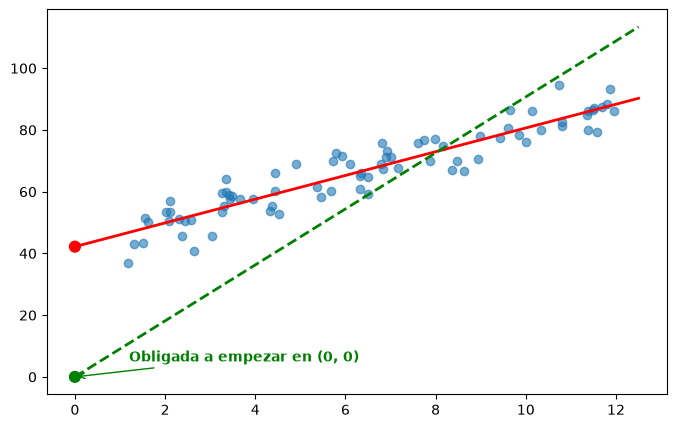

In [ ]:
import statsmodels.api as sm
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm


df = pd.read_csv("../data/study_scores.csv")
train_df = df[df['split'] == 'train']

# Ajustar ambos modelos (CON constante y SIN constante)
X_with_const = sm.add_constant(train_df['study_hours'])
y = train_df['exam_score']

model_with_const = sm.OLS(y, X_with_const).fit()
model_no_const = sm.OLS(y, train_df['study_hours']).fit()

# Generar el rango de horas desde 0 hasta 12.5 para trazar ambas rectas
x_vals = np.linspace(0, 12.5, 100)
y_with = ( model_with_const.params['const'] + model_with_const.params['study_hours'] * x_vals)
y_no = model_no_const.params['study_hours'] * x_vals


plt.figure(figsize=(8, 5))

# Puntos reales
plt.scatter(
    train_df['study_hours'],
    train_df['exam_score'],
    alpha=0.6,
    label='Datos reales (train)',
)


plt.plot(
    x_vals,
    y_with,
    color='red',
    linewidth=2,
    label=(
        f'Con constante (β0 = {model_with_const.params["const"]:.1f}, β1 ='
        f' {model_with_const.params["study_hours"]:.2f})'
    ),
)


plt.plot(
    x_vals,
    y_no,
    color='green',
    linestyle='--',
    linewidth=2,
    label=('Sin constante (β0 = 0, β1 =' f' {model_no_const.params["study_hours"]:.2f})'
    ),
)


plt.scatter(
    [0, 0],
    [model_with_const.params['const'], 0],
    color=['red', 'green'],
    zorder=5,
    s=60,
)

plt.annotate(
    'Obligada a empezar en (0, 0)',
    xy=(0, 0),
    xytext=(1.2, 5),
    arrowprops=dict(arrowstyle='->', color='green'),
    color='green',
    fontweight='bold',
)


plt.title('Diferencia entre modelo CON término constante y SIN término constante')
plt.xlabel('Horas de estudio (study_hours)')
plt.ylabel('Nota del examen (exam_score)')
plt.xlim(-0.5, 12.5)
plt.ylim(-5, 100)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# 3.2 Inferencia y Análisis

##3.2.1 Escribir la pendiente, su intervalo de confianza del (95%), y su p-valor contra una pendiente nula, proporcionar el valor de R^2

- La pendiente:  $$\beta_1=3,845 $$  representa en promedio que por cada hora adicional que un estudiante dedique a estudiar, su nota del examen aumentara aproximadamente 3,845 puntos.
- Intervarlo de Confianza (95%)
  Para encontrar los intervalos de confianza usamos: 
  $$\text{IC}_{95\%} = \hat{\beta}_1 \pm \left( t_{\text{crítico}} \times \text{Error Estándar} \right)$$

  donde: 
   - Pendiente estimada ($\hat{\beta}_1$): $3.8450$
   - t-criti
  $$t = \frac{\text{Estimación del coeficiente} - \text{Valor bajo la hipótesis nula}}{\text{Error Estándar del coeficiente}}$$

  - Valor bajo la hipótesis nula: ($H_0$): Asumimos que la pendiente es cero ($\beta_1 = 0$, es decir, que no hay relación).

  - Error Estándar de la pendiente: Mide que tanto variaria la pendiente si se repite el estudio con otro grupo de estudiantes
  
    $$\text{SE}(\hat{\beta}_1) = \frac{\text{RSE}_{\text{train}}}{\sqrt{\sum (X_i - \bar{X})^2}} = \sqrt{\frac{s^2}{\sum (X_i - \bar{X})^2}}$$
  
  para hallar el error estandar:
    -  Calcular Suma de Cuadrados de los residuos: $$\text{RSS} = \sum (y_i - \hat{y}_i)^2 = \mathbf{1800.43}$$
    - Hallamos la varianza residual($s^2$) : Como tenemos $n = 80$ observaciones y estimamos $2$ parámetros ($\beta_0$ y $\beta_1$), quedan $80 - 2 = 78$ grados de libertad.
  
        $$s^2 = \frac{1800.43}{78} = \mathbf{23.0824}$$
    - Calcular la dispersión de las horas de estudio ($\text{SS}_X$):
        $$\sum (X_i - \bar{X})^2 = \mathbf{851.99}$$
    - Aplicando los valores a la formula del Error Estandar: 
        $$\text{SE}(\hat{\beta}_1) = \sqrt{\frac{23.0824}{851.99}} = \sqrt{0.027092} = \mathbf{0.164598} \approx \mathbf{0.165}$$

  *aplicando estos valores para hallar el intervalo de confianza al 95%*

    $$\text{IC}_{95\%} = \hat{\beta}_1 \pm \left( t_{\text{crítico}} \times \text{Error Estándar} \right)$$

    - Límite inferior ([0.025): $3.8450 - 0.3277 = 3.5173 \approx \mathbf{3.52}$
    - Límite superior (0.975]): $3.8450 + 0.3277 = 4.1727 \approx \mathbf{4.17}$
  
- El p-valor frente a una pendiente nula:
  - ($H_0: \beta_1 = 0$) => Estudiar no tiene ningun efecto real sobre la nota
  - ($H_1$): $\beta_1 \neq 0$ (Estudiar sí tiene un efecto real sobre la nota).

  Calculamos sus valores:
    $$t = \frac{\hat{\beta}_1 - 0}{\text{SE}(\hat{\beta}_1)} = \frac{3.8450}{0.1646} = \mathbf{23.360}$$

    hallamos el p-valor en notación cientifica: 
    $$\text{p-valor} = 2 \cdot P\left(T_{78} \geq \vert{}23.360\vert{}\right) = 2 \cdot \left(1 - F_{t,\,78}(23.360)\right) = \mathbf{5.90 \times 10^{-37}}$$

    Dado que p-valor es menor a 0,05 se rechaza la hipotesis nula ($H_0$), demostrando que si existe una relación entre las horas de estudio y la nota del examen, es una relación directa fuera del azar.
  
-  Coeficiente de determinación ($R^2$):
  
  $$R^2 = \frac{\text{SSR}}{\text{SST}}$$

  Calculamos sus componentes:
   
  - Calculamos Suma de Cuadrados Total (SST) 
  $$\text{SST} = \sum_{i=1}^{n} (y_i - \bar{y})^2 = 14\,395.96$$
  
  - Calculamos Suma de Cuadrados del Error (SSE)
    $$\text{SSE} = \mathbf{1\,800.43}$$
- Reemplazamos en la formula:
    $$\frac{\text{SSE}}{\text{SST}} = \frac{1\,800.43}{14\,395.96} = 0.125 $$
  por lo tanto:
  $$R^2 = 1 - 0.125 = \mathbf{0.875} \text{ (o } 87.5\% \text{)}$$

  Concluimos:
  - Que el modelo de horas de estudio explica el 87.5% del porque los alumnos sacan diferentes notas.
  - Sólo un 12.5% de diferencias en las notas se pueden deber a factores externos
  
## 3.2.2 ¿Por qué el p-valor por sí mismo es insuficiente?
- Los p-valores solo responden a una pregunta binaria: ¿Existe o no existe una relación entre la cantidad de horas de estudio y la nota obtenida?
- Los p-valores sirve para indicar si el modelo predecir con precisión por muy bajo que este sea.
  
La evalución del modelo de regresión es efectiva si se mide no solo el p-valor sino combinado conjutamente con el intervalo de confianza, el coeficiente de determinación y los análisis de residuos




In [63]:

df_notas = pd.read_csv("../data/study_scores.csv")
train_notas=df_notas[df_notas["split"]=="train"].drop(columns="split")

print("\nDatos de puntaje de notas\n")
display(train_notas.head())



Datos de puntaje de notas



,student_id,study_hours,exam_score
0,S001,8.47,70.09
1,S002,5.72,69.83
2,S003,10.01,76.22
4,S005,5.38,61.54
5,S006,3.03,45.56


RESUMEN DEL DF DE PUNTAJE DE LAS NOTAS


,study_hours,exam_score
count,80.000000,80.000000
mean,6.413125,66.855250
std,3.283995,13.499159
min,1.170000,37.010000
25%,3.405000,57.387500
50%,6.330000,67.165000
75%,9.097500,77.142500
max,11.950000,94.710000


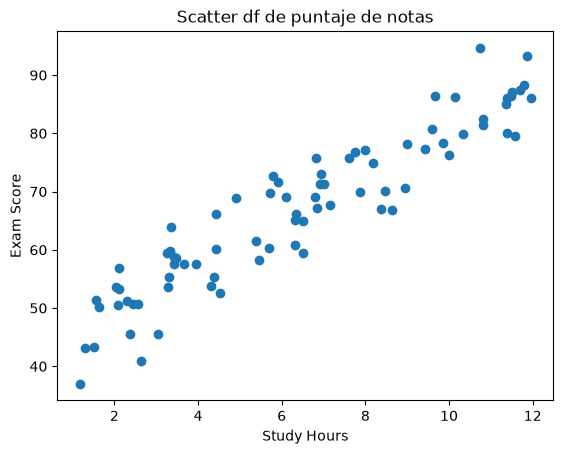

In [66]:
print("RESUMEN DEL DF DE PUNTAJE DE LAS NOTAS")
display(train_notas.describe())

plt.title("Scatter df de puntaje de notas")
plt.xlabel("Study Hours")
plt.ylabel("Exam Score")

plt.scatter(train_notas["study_hours"], train_notas["exam_score"])
plt.show()



Datos de precio de rentas



,apartment_id,floor_area_m2,bedrooms,building_age_years,distance_center_km,renovated,monthly_rent_eur
0,A001,87.9,2,16,6.83,1,1208.87
1,A002,91.3,3,41,8.98,0,1389.30
2,A003,70.3,1,28,1.64,0,1417.31
4,A005,101.0,3,36,1.16,0,1789.75
6,A007,97.6,3,5,14.01,1,1307.73


RESUMEN DEL DF DE PRECIO DE RENTAS


,floor_area_m2,bedrooms,building_age_years,distance_center_km,renovated,monthly_rent_eur
count,135.000000,135.000000,135.000000,135.000000,135.000000,135.000000
mean,80.374815,2.392593,24.118519,9.315778,0.407407,1295.899259
std,22.895935,0.915018,13.120596,4.898400,0.493182,434.938451
min,38.000000,1.000000,0.000000,0.550000,0.000000,522.280000
25%,64.650000,2.000000,13.000000,5.145000,0.000000,990.940000
50%,79.500000,2.000000,25.000000,8.980000,0.000000,1220.240000
75%,96.000000,3.000000,34.500000,13.715000,1.000000,1470.105000
max,133.600000,4.000000,45.000000,17.460000,1.000000,2826.090000


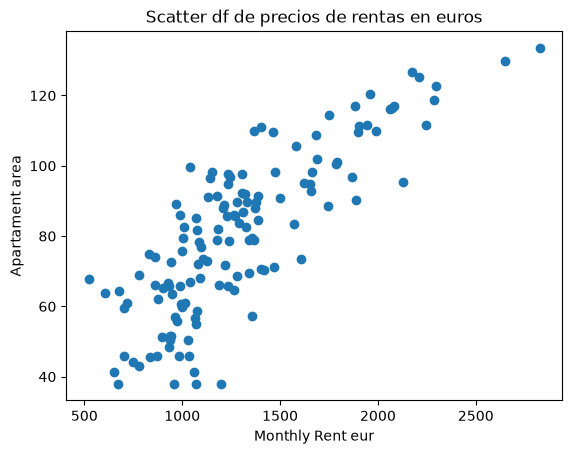

In [65]:
df_rentas = pd.read_csv("../data/apartment_rents.csv")
train_rentas=df_rentas[df_rentas["split"]=="train"].drop(columns="split")

print("\nDatos de precio de rentas\n")
display(train_rentas.head())

print("RESUMEN DEL DF DE PRECIO DE RENTAS")
display(train_rentas.describe())

plt.title("Scatter df de precios de rentas en euros")
plt.xlabel("Monthly Rent eur")

plt.ylabel("Apartament area")
plt.scatter(train_rentas["monthly_rent_eur"], train_rentas["floor_area_m2"])
plt.show()